In [2]:
import pandas as pd

# Veri setimizi okuyoruz
veri = pd.read_excel("../data/raw/googleplaystore.xlsx")

# Verinin ilk 5 satırına bakalım
veri.head()


,"App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver",Unnamed: 1
0,Photo Editor & Candy Camera & Grid & ScrapBook...,NaN
1,"Coloring book moana,ART_AND_DESIGN,3.9,967,14M...","Pretend Play,""January 15, 2018"",2.0.0,4.0.3 an..."
2,"U Launcher Lite â€“ FREE Live Cool Themes, Hid...",NaN
3,"Sketch - Draw & Paint,ART_AND_DESIGN,4.5,21564...",NaN
4,"Pixel Draw - Number Art Coloring Book,ART_AND_...","Creativity,""June 20, 2018"",1.1,4.4 and up"


In [3]:
# Veri setindeki mevcut durumu ve sütunları detaylıca inceliyoruz
print("Veri setinin boyutu (Satır, Sütun):", veri.shape)
print("\nŞu anki hatalı sütun isimleri:")
print(veri.columns.tolist())

Veri setinin boyutu (Satır, Sütun): (10841, 2)

Şu anki hatalı sütun isimleri:
['App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver', 'Unnamed: 1']


In [4]:
import io

# 1. Bozuk verideki satırları tek tek gezip, virgüllerinden ayırarak onarıyoruz
satirlar = [veri.columns[0]] # Yapışık başlıkları al
for index, row in veri.iterrows():
    if pd.isna(row.iloc[1]):
        satirlar.append(str(row.iloc[0]))
    else:
        # Taşan verileri ana veriyle tekrar birleştir
        satirlar.append(str(row.iloc[0]) + "," + str(row.iloc[1]))

# 2. Onarılmış veriyi Pandas ile düzgün bir tabloya (DataFrame) dönüştürüyoruz
temiz_csv = "\n".join(satirlar)
# on_bad_lines='skip' komutu, kurtarılamayacak kadar bozuk olan birkaç satırı atlamamızı sağlar
df = pd.read_csv(io.StringIO(temiz_csv), on_bad_lines='skip')

# 3. Temizlenmiş ve sütunlarına ayrılmış yeni tablomuza bakalım!
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
2,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,"50,000+",Free,0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up
3,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19M,"50,000+",Free,0,Everyone,Art & Design,"April 26, 2018",1.1,4.0.3 and up
4,Infinite Painter,ART_AND_DESIGN,4.1,36815,29M,"1,000,000+",Free,0,Everyone,Art & Design,"June 14, 2018",6.1.61.1,4.2 and up


In [5]:
# Sadece 'EDUCATION' ve 'FAMILY' kategorilerindeki uygulamaları filtreleyelim
hedef_kategoriler = ['EDUCATION', 'FAMILY']
df_cocuk = df[df['Category'].isin(hedef_kategoriler)].copy()

# Elimizde incelemek için kaç uygulama kaldığına bakalım
print("İncelenecek uygulama sayısı:", len(df_cocuk))

# Bu uygulamaların kaçı "Ücretsiz" (Free), kaçı "Ücretli" (Paid) bakalım
print("\nÜcretsiz ve Ücretli Dağılımı:")
print(df_cocuk['Type'].value_counts())

İncelenecek uygulama sayısı: 1642

Ücretsiz ve Ücretli Dağılımı:
Type
Free    1526
Paid     115
Name: count, dtype: int64


In [6]:
# 1. İndirme sayılarını (Installs) temizleyip sayı formatına çeviriyoruz
df_cocuk['Installs'] = df_cocuk['Installs'].str.replace('+', '')
df_cocuk['Installs'] = df_cocuk['Installs'].str.replace(',', '')
df_cocuk['Installs'] = pd.to_numeric(df_cocuk['Installs'], errors='coerce')

# 2. Değerlendirme puanlarını (Rating) matematiksel işleme uygun hale getiriyoruz
df_cocuk['Rating'] = pd.to_numeric(df_cocuk['Rating'], errors='coerce')

print("Temizleme tamamlandı! İşte pazarın devleri (En çok indirilen 5 ücretsiz uygulama):")
# Ücretsizleri al, indirme sayısına göre büyükten küçüğe sırala ve ilk 5'i göster
populer_ucretsizler = df_cocuk[df_cocuk['Type'] == 'Free'].sort_values(by='Installs', ascending=False)
populer_ucretsizler[['App', 'Category', 'Installs', 'Rating']].head()

Temizleme tamamlandı! İşte pazarın devleri (En çok indirilen 5 ücretsiz uygulama):


,App,Category,Installs,Rating
5070,Google Play Games,FAMILY,1000000000,4.3
3215,Pou,FAMILY,500000000,4.3
3326,Candy Crush Saga,FAMILY,500000000,4.4
3224,My Talking Tom,FAMILY,500000000,4.5
3433,Talking Tom Cat 2,FAMILY,100000000,4.3


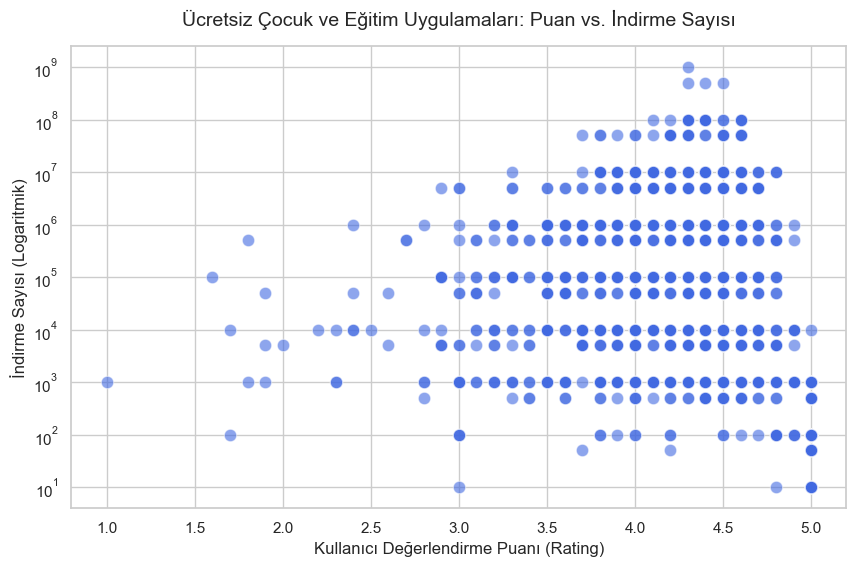

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiğin boyutunu ve tasarım temasını ayarlıyoruz
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Puan (Rating) ve İndirme Sayısı (Installs) arasındaki ilişkiyi gösteren bir saçılım grafiği çiziyoruz
sns.scatterplot(data=df_cocuk[df_cocuk['Type'] == 'Free'], 
                x='Rating', 
                y='Installs', 
                alpha=0.6, 
                color='royalblue',
                edgecolor='w',
                s=80)

# Milyarlarca indirmeyi grafikte düzgün gösterebilmek için Y eksenini logaritmik yapıyoruz
plt.yscale('log')
plt.title("Ücretsiz Çocuk ve Eğitim Uygulamaları: Puan vs. İndirme Sayısı", fontsize=14, pad=15)
plt.xlabel("Kullanıcı Değerlendirme Puanı (Rating)", fontsize=12)
plt.ylabel("İndirme Sayısı (Logaritmik)", fontsize=12)

# Grafiği ekrana yansıt
plt.show()